# Telco customer churn: exploratory analysis

Goal: understand **who churns and why** before modelling, and find signals that a retention team can act on.

Dataset: IBM Telco Customer Churn, 7,043 customers, 21 fields (demographics, services, contract, billing) and a `Churn` flag for customers who left in the last month.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn.data import load_dataset
from churn.features import add_features

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
df = add_features(load_dataset())
print(f'{len(df):,} customers, {df.shape[1]} columns')
df.head()

7,043 customers, 25 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,num_services,avg_monthly_spend,charge_increase,is_new_customer,auto_payment
customerID,,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,Yes,Electronic check,29.85,29.85,0,2,29.850000,0.000000,1,0
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,Mailed check,56.95,1889.50,0,4,55.573529,1.376471,0,0
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Yes,Mailed check,53.85,108.15,1,4,54.075000,-0.225000,1,0
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,Bank transfer (automatic),42.30,1840.75,0,4,40.905556,1.394444,0,1
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Yes,Electronic check,70.70,151.65,1,2,75.825000,-5.125000,1,0


## 1. Data quality

In [2]:
quality = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                        'unique': df.nunique()})
print('Duplicate customer IDs:', df.index.duplicated().sum())
quality

Duplicate customer IDs: 0


,dtype,missing,unique
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3
OnlineBackup,str,0,3


The only quality issue in the raw file is `TotalCharges`: it is stored as text and is blank for 11 customers. All of them have `tenure = 0`: they signed up but have not been billed yet, so `churn.data.clean` sets them to 0 instead of dropping or imputing.

## 2. How big is the problem?

In [3]:
churn_rate = df['Churn'].mean()
lost_mrr = df.loc[df['Churn'] == 1, 'MonthlyCharges'].sum()
print(f'Churn rate: {churn_rate:.1%}')
print(f'Monthly recurring revenue lost to churn: ${lost_mrr:,.0f} '
      f'({lost_mrr / df.MonthlyCharges.sum():.1%} of total)')

Churn rate: 26.5%
Monthly recurring revenue lost to churn: $139,131 (30.5% of total)


About one customer in four churns, and churners pay **more** than average, so the revenue share lost is even larger than the customer share.

## 3. Churn rate by customer segment

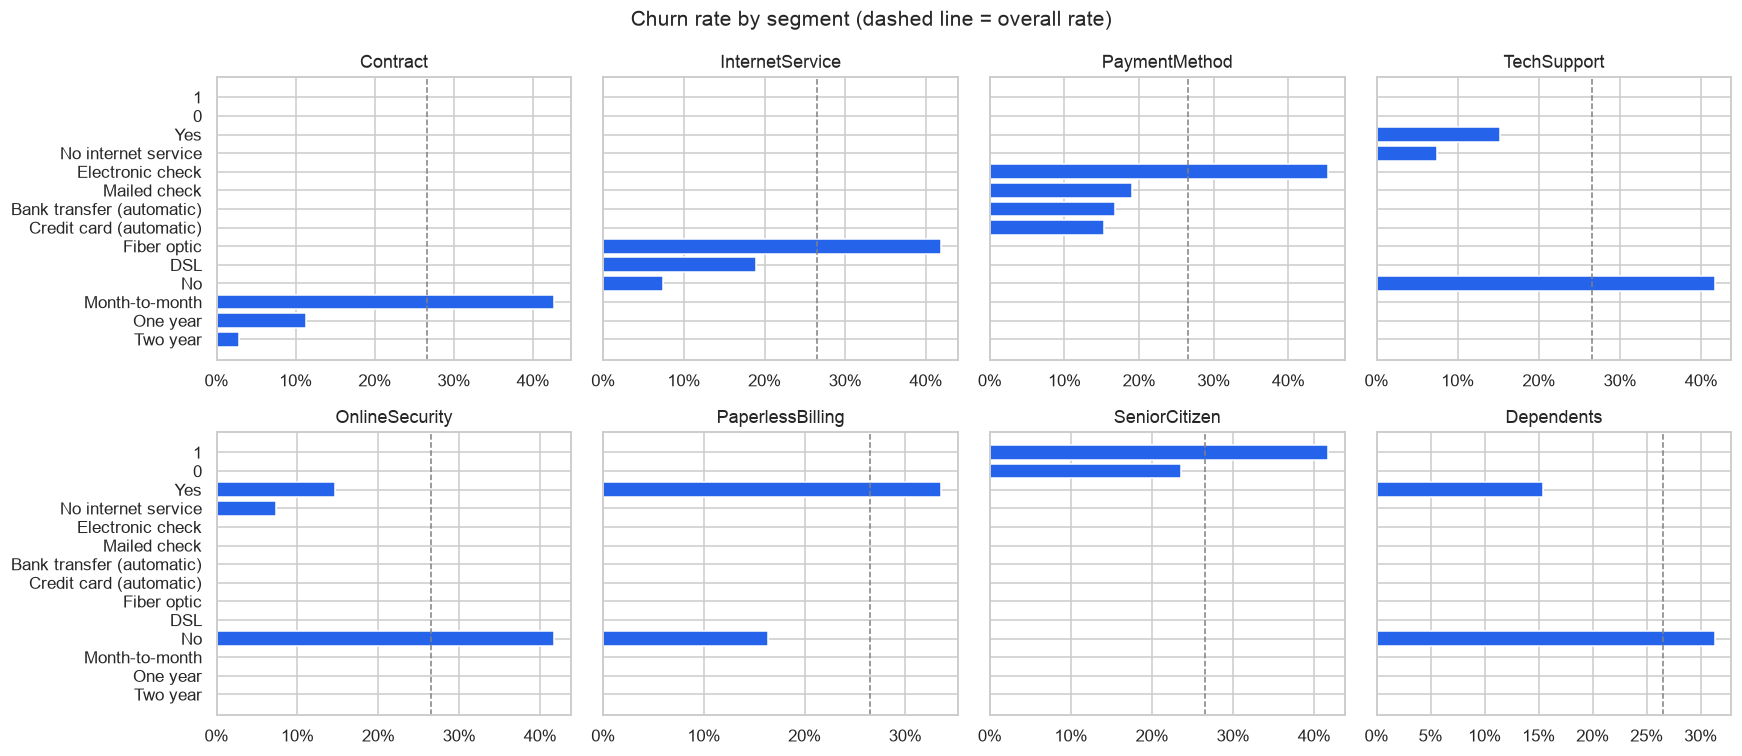

In [4]:
segments = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport',
            'OnlineSecurity', 'PaperlessBilling', 'SeniorCitizen', 'Dependents']
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, col in zip(axes.flat, segments):
    rates = df.groupby(col)['Churn'].mean().sort_values()
    ax.barh(rates.index.astype(str), rates.values, color='#2563eb')
    ax.axvline(churn_rate, color='grey', ls='--', lw=1)
    ax.set_title(col)
    ax.xaxis.set_major_formatter('{x:.0%}')
fig.suptitle('Churn rate by segment (dashed line = overall rate)', fontsize=14)
fig.tight_layout()

**Takeaways**

* **Contract type is the strongest single signal**: month-to-month customers churn ~15x more than two-year customers. Converting customers to annual contracts is the most obvious retention lever.
* **Fiber optic** customers churn far more than DSL customers despite the faster product, a hint of price or service-quality issues worth investigating.
* **Electronic check** payers churn much more than customers on automatic payments.
* Customers **without tech support / online security** churn almost 3x as often (42% vs 15%): bundling these services could be part of a retention offer.

## 4. Tenure and charges

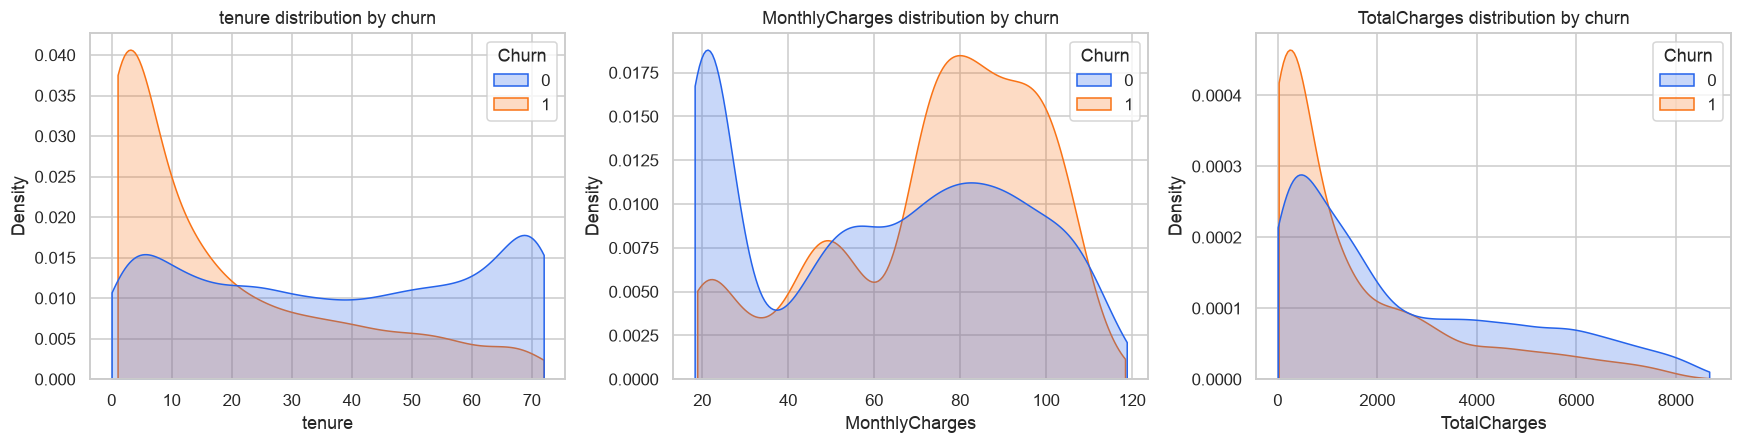

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for col, ax in zip(['tenure', 'MonthlyCharges', 'TotalCharges'], axes):
    sns.kdeplot(data=df, x=col, hue='Churn', common_norm=False, fill=True, ax=ax,
                cut=0, palette={0: '#2563eb', 1: '#f97316'})
    ax.set_title(f'{col} distribution by churn')
fig.tight_layout()

,churn_rate,customers
tenure,,
0-6,52.9%,1481
7-12,35.9%,705
13-24,28.7%,1024
25-48,20.4%,1594
49-72,9.5%,2239


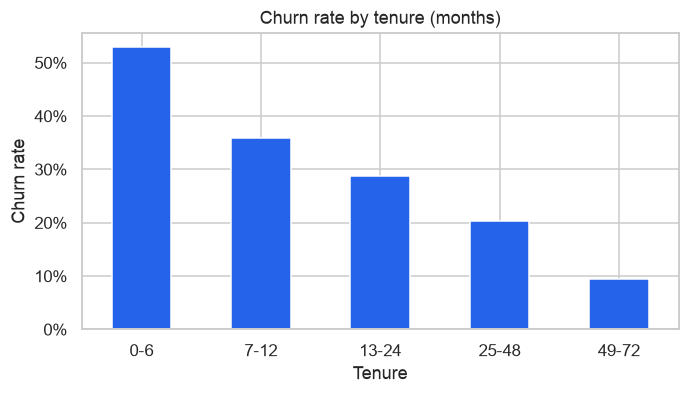

In [6]:
tenure_bins = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                     labels=['0-6', '7-12', '13-24', '25-48', '49-72'])
by_tenure = df.groupby(tenure_bins, observed=True)['Churn'].agg(['mean', 'size'])
by_tenure.columns = ['churn_rate', 'customers']
ax = by_tenure['churn_rate'].plot.bar(color='#2563eb', figsize=(7, 3.5), rot=0)
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set(title='Churn rate by tenure (months)', xlabel='Tenure', ylabel='Churn rate')
by_tenure.style.format({'churn_rate': '{:.1%}'})

Churn is concentrated in the **first months** of the relationship: more than half of customers in their first 6 months leave (53%), against under 10% after four years. Onboarding is the critical window for retention.

## 5. Engineered features

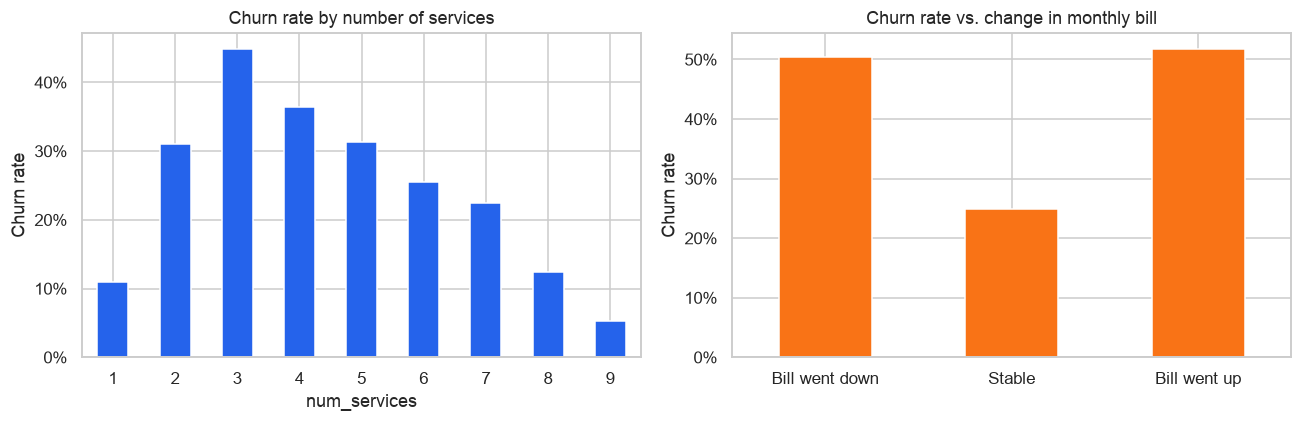

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby('num_services')['Churn'].mean().plot.bar(ax=axes[0], color='#2563eb', rot=0)
axes[0].set(title='Churn rate by number of services', ylabel='Churn rate')
axes[0].yaxis.set_major_formatter('{x:.0%}')
increase = pd.cut(df['charge_increase'], [-100, -5, 5, 100],
                  labels=['Bill went down', 'Stable', 'Bill went up'])
df.groupby(increase, observed=True)['Churn'].mean().plot.bar(ax=axes[1], color='#f97316',
                                                              rot=0)
axes[1].set(title='Churn rate vs. change in monthly bill', ylabel='Churn rate', xlabel='')
axes[1].yaxis.set_major_formatter('{x:.0%}')
fig.tight_layout()

* `num_services`: customers with a single service churn less than customers with a few, but heavily-bundled customers are the stickiest; the relationship is non-linear, which tree models capture well.
* `charge_increase` compares the current bill with the historical average bill. Customers whose bill **changed in either direction** by more than $5 churn about twice as often as customers with a stable bill (~50% vs. 25%). Only ~6% of customers are affected, but it is a pricing-change signal that is not visible in any raw column.

## 6. Correlation between numeric features

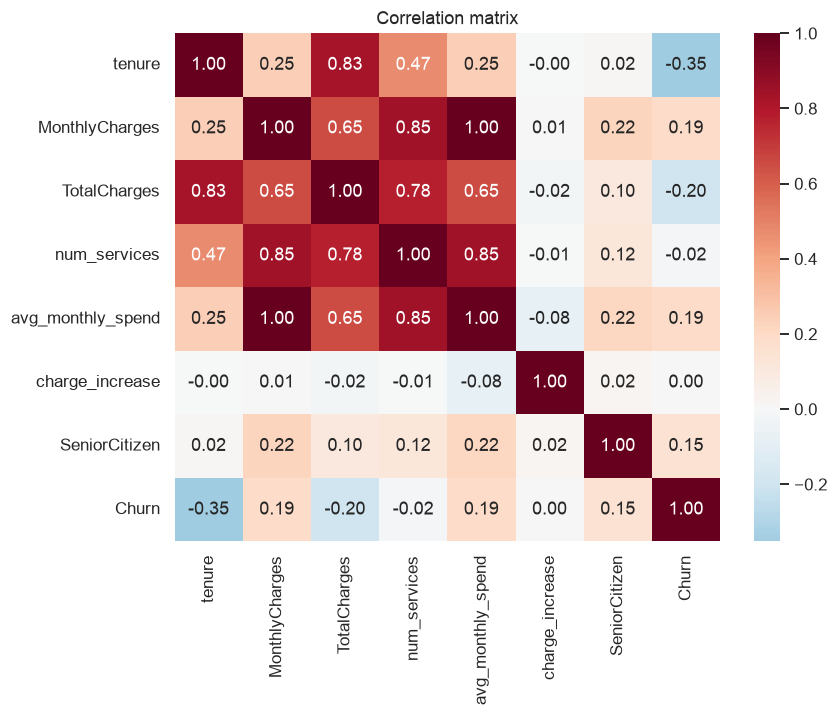

In [8]:
numeric = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services',
           'avg_monthly_spend', 'charge_increase', 'SeniorCitizen', 'Churn']
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation matrix');

`TotalCharges` is almost a product of `tenure` and `MonthlyCharges` (r ≈ 0.83 with tenure). That collinearity is harmless for tree models and handled by regularisation in logistic regression, so all three are kept.

## 7. Conclusions for modelling

1. The target is imbalanced (26.5% positives) → evaluate with **PR-AUC** and ROC-AUC, not accuracy, and use a stratified split.
2. Strong signals are categorical (contract, payment method, internet type) → one-hot encoding inside a scikit-learn pipeline so the API can take raw records.
3. The business question is *who to contact*, not *who will churn* → choose the decision threshold by **campaign profit**, not by F1 or 0.5 (see `src/churn/business.py` and the README).